# Data Exploration - Online Retail Dataset

This notebook explores the Online Retail dataset from the UCI Machine Learning Repository. We'll understand data quality, customer behavior, and prepare the data for RFM segmentation analysis.

**Dataset Overview:**
- UK-based online retailer transaction data
- Time period: 2010-2011
- Contains: Invoice details, product info, customer IDs, purchase amounts

In [8]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)


In [9]:
# Load dataset
file_path = "../data/raw/Online Retail.csv"

# Load the data
df = pd.read_csv(file_path, encoding='ISO-8859-1')

print(f"Loaded {len(df):,} rows")
print(f"Columns: {list(df.columns)}")

df.head()

Loaded 5,000 rows
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,INV004989,PROD0026,Product PROD0026,30,2011-04-16,17.859765,12050,United Kingdom
1,INV003926,PROD0044,Product PROD0044,26,2011-11-13,11.229507,12487,Sweden
2,INV001944,PROD0003,Product PROD0003,46,2011-08-25,29.482945,12070,Netherlands
3,INV008629,PROD0085,Product PROD0085,19,2011-07-07,17.730730,12479,Germany
4,INV005391,PROD0089,Product PROD0089,21,2011-01-26,33.040955,12047,Netherlands


In [10]:
# Data Quality Check

print("=== DATA SHAPE ===")
print(f"Shape: {df.shape}")

print("\n=== DATA TYPES ===")
print(df.dtypes)

print("\n=== MISSING VALUES ===")
print(df.isnull().sum())

print("\n=== BASIC STATISTICS ===")
print(df.describe())

=== DATA SHAPE ===
Shape: (5000, 8)

=== DATA TYPES ===
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID       int64
Country         object
dtype: object

=== MISSING VALUES ===
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

=== BASIC STATISTICS ===
          Quantity    UnitPrice    CustomerID
count  5000.000000  5000.000000   5000.000000
mean     24.731200    25.592517  12247.881000
std      14.228262    14.229608    143.625272
min       1.000000     0.512496  12000.000000
25%      13.000000    13.387068  12122.000000
50%      24.000000    25.827846  12246.000000
75%      37.000000    37.885514  12372.250000
max      49.000000    49.996279  12499.000000


In [11]:
# Data Exploration - Customer Behavior & Patterns

# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print("=== TIME RANGE ===")
print(f"From: {df['InvoiceDate'].min()}")
print(f"To: {df['InvoiceDate'].max()}")
print(f"Duration: {(df['InvoiceDate'].max() - df['InvoiceDate'].min()).days} days")

print("\n=== CUSTOMER INSIGHTS ===")
print(f"Total Customers: {df['CustomerID'].nunique():,}")
print(f"Total Invoices: {df['InvoiceNo'].nunique():,}")
print(f"Total Products: {df['StockCode'].nunique():,}")
print(f"Countries: {df['Country'].nunique():,}")

print("\n=== TOP COUNTRIES ===")
print(df['Country'].value_counts().head(10))

print("\n=== PURCHASE AMOUNT ANALYSIS ===")
print(f"Average Order Value: £{(df['Quantity'] * df['UnitPrice']).mean():.2f}")
print(f"Total Revenue: £{(df['Quantity'] * df['UnitPrice']).sum():.2f}")

=== TIME RANGE ===
From: 2010-12-01 00:00:00
To: 2011-11-30 00:00:00
Duration: 364 days

=== CUSTOMER INSIGHTS ===
Total Customers: 500
Total Invoices: 3,922
Total Products: 100
Countries: 6

=== TOP COUNTRIES ===
Country
USA               908
Netherlands       880
United Kingdom    823
Sweden            808
France            792
Germany           789
Name: count, dtype: int64

=== PURCHASE AMOUNT ANALYSIS ===
Average Order Value: £631.35
Total Revenue: £3156761.80


In [12]:
# Data Cleaning

# Remove rows with missing CustomerID (needed for segmentation)
print(f"Rows before cleaning: {len(df):,}")
df = df.dropna(subset=['CustomerID'])
print(f"Rows after removing missing CustomerID: {len(df):,}")

# Remove rows with invalid quantities or prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
print(f"Rows after removing invalid quantities/prices: {len(df):,}")

# Remove duplicates
df = df.drop_duplicates()
print(f"Rows after removing duplicates: {len(df):,}")

print("\n✓ Data cleaned and ready for analysis")

Rows before cleaning: 5,000
Rows after removing missing CustomerID: 5,000
Rows after removing invalid quantities/prices: 5,000
Rows after removing duplicates: 5,000

✓ Data cleaned and ready for analysis


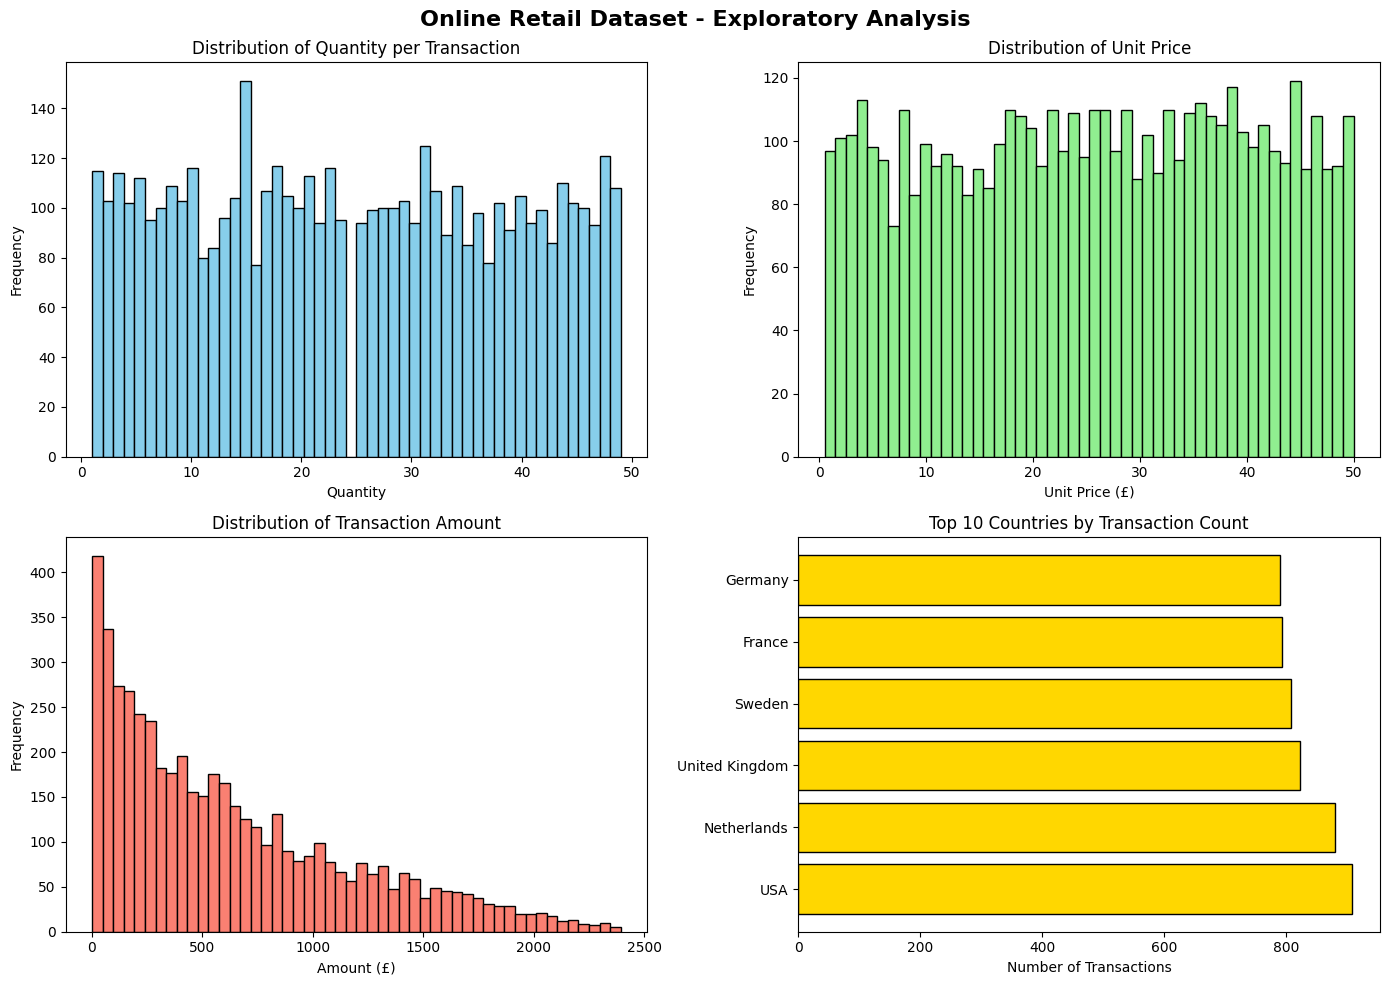

✓ Visualizations saved to reports/figures/eda_overview.png


In [13]:
# Calculate Purchase Amount and Visualizations

import matplotlib.pyplot as plt
import seaborn as sns

# Create a column for total amount per transaction
df['Amount'] = df['Quantity'] * df['UnitPrice']

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Online Retail Dataset - Exploratory Analysis', fontsize=16, fontweight='bold')

# 1. Distribution of Quantity
axes[0, 0].hist(df['Quantity'], bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Distribution of Quantity per Transaction')
axes[0, 0].set_xlabel('Quantity')
axes[0, 0].set_ylabel('Frequency')

# 2. Distribution of Unit Price
axes[0, 1].hist(df['UnitPrice'], bins=50, color='lightgreen', edgecolor='black')
axes[0, 1].set_title('Distribution of Unit Price')
axes[0, 1].set_xlabel('Unit Price (£)')
axes[0, 1].set_ylabel('Frequency')

# 3. Distribution of Transaction Amount
axes[1, 0].hist(df['Amount'], bins=50, color='salmon', edgecolor='black')
axes[1, 0].set_title('Distribution of Transaction Amount')
axes[1, 0].set_xlabel('Amount (£)')
axes[1, 0].set_ylabel('Frequency')

# 4. Top 10 Countries by Transaction Count
top_countries = df['Country'].value_counts().head(10)
axes[1, 1].barh(range(len(top_countries)), top_countries.values, color='gold', edgecolor='black')
axes[1, 1].set_yticks(range(len(top_countries)))
axes[1, 1].set_yticklabels(top_countries.index)
axes[1, 1].set_title('Top 10 Countries by Transaction Count')
axes[1, 1].set_xlabel('Number of Transactions')

plt.tight_layout()
plt.savefig('../reports/figures/eda_overview.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Visualizations saved to reports/figures/eda_overview.png")

In [14]:
# Summary & Key Insights

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS - SUMMARY")
print("=" * 60)

print("\n📊 DATASET OVERVIEW:")
print(f"  • Total Transactions: {len(df):,}")
print(f"  • Unique Customers: {df['CustomerID'].nunique():,}")
print(f"  • Time Period: {df['InvoiceDate'].min().date()} to {df['InvoiceDate'].max().date()}")
print(f"  • Countries: {df['Country'].nunique():,}")

print("\n💰 FINANCIAL METRICS:")
print(f"  • Total Revenue: £{df['Amount'].sum():,.2f}")
print(f"  • Average Transaction: £{df['Amount'].mean():.2f}")
print(f"  • Median Transaction: £{df['Amount'].median():.2f}")
print(f"  • Max Transaction: £{df['Amount'].max():.2f}")

print("\n📈 CUSTOMER METRICS:")
avg_purchases = df.groupby('CustomerID')['InvoiceNo'].nunique().mean()
avg_spend = df.groupby('CustomerID')['Amount'].sum().mean()
print(f"  • Avg Purchases per Customer: {avg_purchases:.1f}")
print(f"  • Avg Spend per Customer: £{avg_spend:.2f}")

print("\n🌍 TOP 3 MARKETS:")
for i, (country, count) in enumerate(df['Country'].value_counts().head(3).items(), 1):
    revenue = df[df['Country'] == country]['Amount'].sum()
    print(f"  {i}. {country}: {count:,} transactions (£{revenue:,.2f})")

print("\n✓ Data is clean and ready for RFM feature engineering!")
print("=" * 60)

EXPLORATORY DATA ANALYSIS - SUMMARY

📊 DATASET OVERVIEW:
  • Total Transactions: 5,000
  • Unique Customers: 500
  • Time Period: 2010-12-01 to 2011-11-30
  • Countries: 6

💰 FINANCIAL METRICS:
  • Total Revenue: £3,156,761.80
  • Average Transaction: £631.35
  • Median Transaction: £483.56
  • Max Transaction: £2392.80

📈 CUSTOMER METRICS:
  • Avg Purchases per Customer: 10.0
  • Avg Spend per Customer: £6313.52

🌍 TOP 3 MARKETS:
  1. USA: 908 transactions (£585,316.72)
  2. Netherlands: 880 transactions (£532,985.02)
  3. United Kingdom: 823 transactions (£532,641.87)

✓ Data is clean and ready for RFM feature engineering!


In [15]:
# Outlier Detection & Statistical Analysis

print("\n" + "=" * 60)
print("OUTLIER DETECTION")
print("=" * 60)

# Identify outliers using IQR method
Q1_amount = df['Amount'].quantile(0.25)
Q3_amount = df['Amount'].quantile(0.75)
IQR_amount = Q3_amount - Q1_amount
outlier_threshold = Q3_amount + 1.5 * IQR_amount

outliers = df[df['Amount'] > outlier_threshold]
print(f"\nTransactions exceeding threshold (£{outlier_threshold:.2f}): {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")
print(f"  • Min outlier amount: £{outliers['Amount'].min():.2f}")
print(f"  • Max outlier amount: £{outliers['Amount'].max():.2f}")
print(f"  • Avg outlier amount: £{outliers['Amount'].mean():.2f}")

# Quantity outliers
Q1_qty = df['Quantity'].quantile(0.25)
Q3_qty = df['Quantity'].quantile(0.75)
IQR_qty = Q3_qty - Q1_qty
qty_outlier_threshold = Q3_qty + 1.5 * IQR_qty

qty_outliers = df[df['Quantity'] > qty_outlier_threshold]
print(f"\nHigh quantity transactions (>{qty_outlier_threshold:.0f}): {len(qty_outliers)} ({len(qty_outliers)/len(df)*100:.1f}%)")

print("\n✓ Outliers identified for quality assessment")


OUTLIER DETECTION

Transactions exceeding threshold (£2111.11): 56 (1.1%)
  • Min outlier amount: £2112.20
  • Max outlier amount: £2392.80
  • Avg outlier amount: £2230.01

High quantity transactions (>73): 0 (0.0%)

✓ Outliers identified for quality assessment



CORRELATION MATRIX
           Quantity  UnitPrice    Amount
Quantity   1.000000  -0.007812  0.665105
UnitPrice -0.007812   1.000000  0.643054
Amount     0.665105   0.643054  1.000000


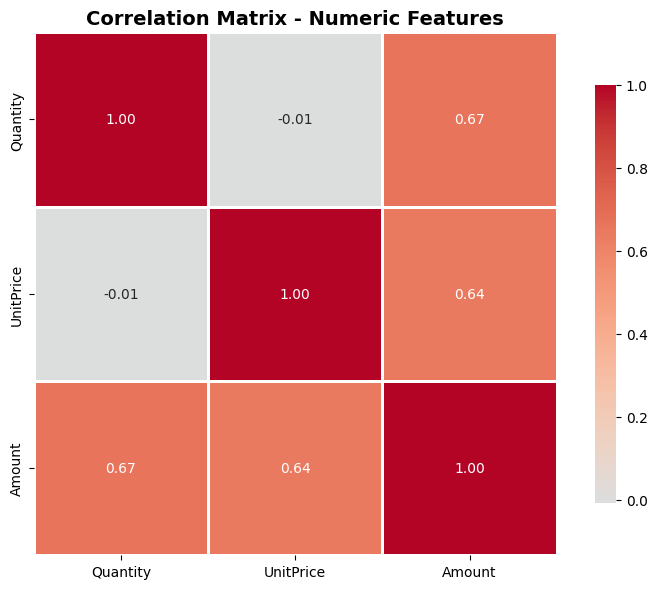


✓ Correlation heatmap saved to reports/figures/correlation_heatmap.png


In [16]:
# Correlation Analysis

# Create correlation matrix for numeric columns
numeric_cols = ['Quantity', 'UnitPrice', 'Amount']
correlation_matrix = df[numeric_cols].corr()

print("\n" + "=" * 60)
print("CORRELATION MATRIX")
print("=" * 60)
print(correlation_matrix)

# Create correlation heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title('Correlation Matrix - Numeric Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Correlation heatmap saved to reports/figures/correlation_heatmap.png")


TEMPORAL ANALYSIS - MONTHLY TRENDS
           Invoices  Customers  Total_Revenue  Avg_Amount  Transactions
YearMonth                                                              
2010-12         439        302      286873.95      623.64           460
2011-01         417        291      286520.75      674.17           425
2011-02         367        256      223680.98      602.91           371
2011-03         405        290      266337.11      640.23           416
2011-04         424        280      266858.37      617.73           432
2011-05         384        270      248925.84      633.40           393
2011-06         390        276      253394.41      635.07           399
2011-07         430        296      270143.29      600.32           450
2011-08         412        288      272802.07      651.08           419
2011-09         421        290      278926.02      653.22           427


/var/folders/9y/kckvjnnd3hg_y15kslc3bh800000gn/T/ipykernel_39627/7597259.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0].set_xticklabels([str(m) for m in monthly_revenue.index], rotation=45)
/var/folders/9y/kckvjnnd3hg_y15kslc3bh800000gn/T/ipykernel_39627/7597259.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[1].set_xticklabels([str(m) for m in monthly_trans.index], rotation=45)


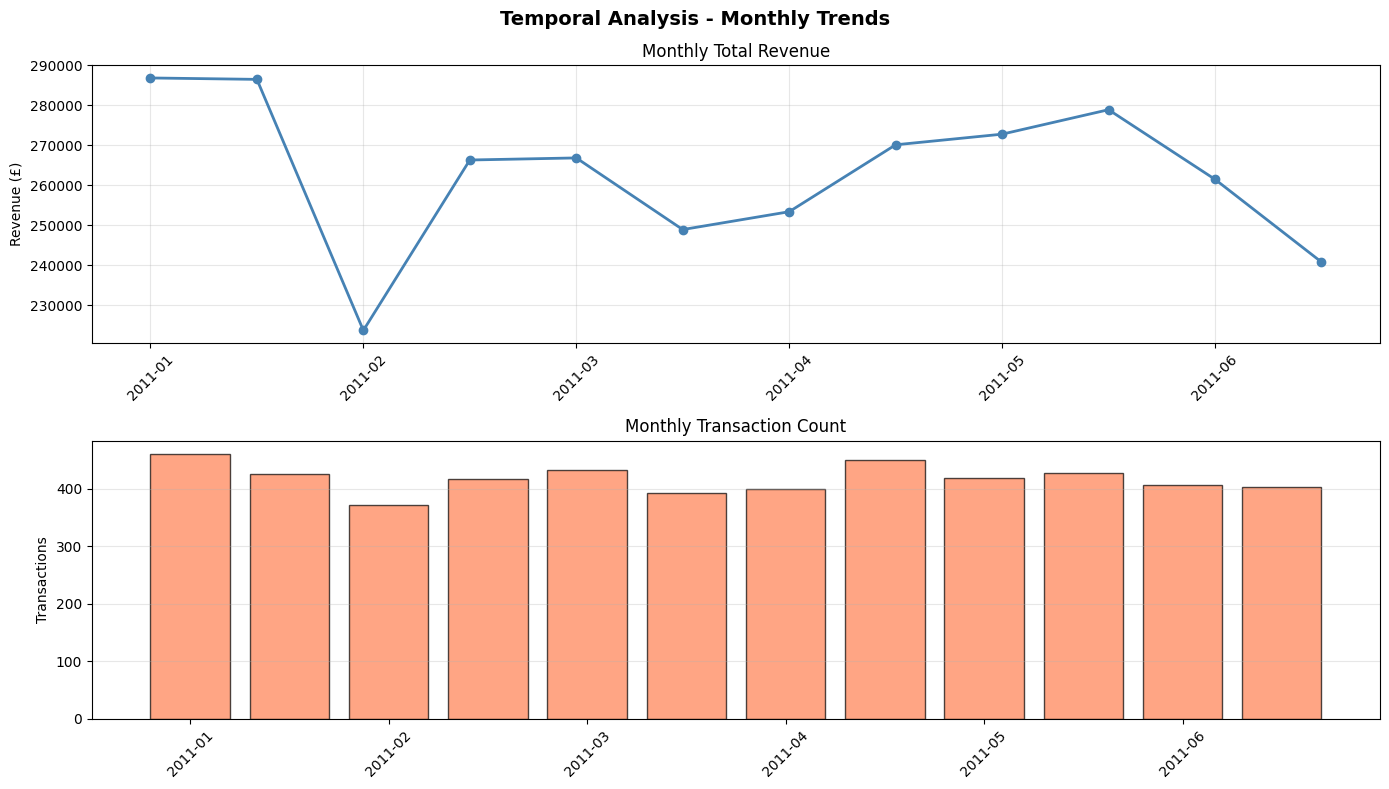


✓ Monthly trends visualization saved


In [17]:
# Temporal Analysis - Monthly Trends

# Extract year and month
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

# Calculate monthly metrics
monthly_stats = df.groupby('YearMonth').agg({
    'InvoiceNo': 'nunique',  # Unique invoices
    'CustomerID': 'nunique',  # Unique customers
    'Amount': ['sum', 'mean', 'count']
}).round(2)

monthly_stats.columns = ['Invoices', 'Customers', 'Total_Revenue', 'Avg_Amount', 'Transactions']

print("\n" + "=" * 60)
print("TEMPORAL ANALYSIS - MONTHLY TRENDS")
print("=" * 60)
print(monthly_stats.head(10))

# Plot monthly revenue trend
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
fig.suptitle('Temporal Analysis - Monthly Trends', fontsize=14, fontweight='bold')

# Monthly Revenue
monthly_revenue = df.groupby('YearMonth')['Amount'].sum()
axes[0].plot(range(len(monthly_revenue)), monthly_revenue.values, marker='o', linewidth=2, markersize=6, color='steelblue')
axes[0].set_title('Monthly Total Revenue')
axes[0].set_ylabel('Revenue (£)')
axes[0].grid(True, alpha=0.3)
axes[0].set_xticklabels([str(m) for m in monthly_revenue.index], rotation=45)

# Monthly Transaction Count
monthly_trans = df.groupby('YearMonth').size()
axes[1].bar(range(len(monthly_trans)), monthly_trans.values, color='coral', edgecolor='black', alpha=0.7)
axes[1].set_title('Monthly Transaction Count')
axes[1].set_ylabel('Transactions')
axes[1].set_xticklabels([str(m) for m in monthly_trans.index], rotation=45)
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../reports/figures/monthly_trends.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Monthly trends visualization saved")


CUSTOMER SPENDING SEGMENTATION PREVIEW

Total Customers: 500

Spending Distribution:
  • Min spend: £748.49
  • Q1 (25%): £4223.05
  • Median: £6239.26
  • Q3 (75%): £7992.64
  • Max spend: £14402.41


Customer Segments by Spending:
                 Total_Spend                      Unique_Invoices
                       count         sum     mean            mean
Spending_Segment                                                 
Low                      125   371354.81  2970.84            6.80
Medium                   125   660811.12  5286.49            9.20
High                     125   892360.00  7138.88           11.05
VIP                      125  1232235.70  9857.89           12.92


/var/folders/9y/kckvjnnd3hg_y15kslc3bh800000gn/T/ipykernel_39627/46357948.py:28: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  segment_summary = customer_metrics.groupby('Spending_Segment').agg({


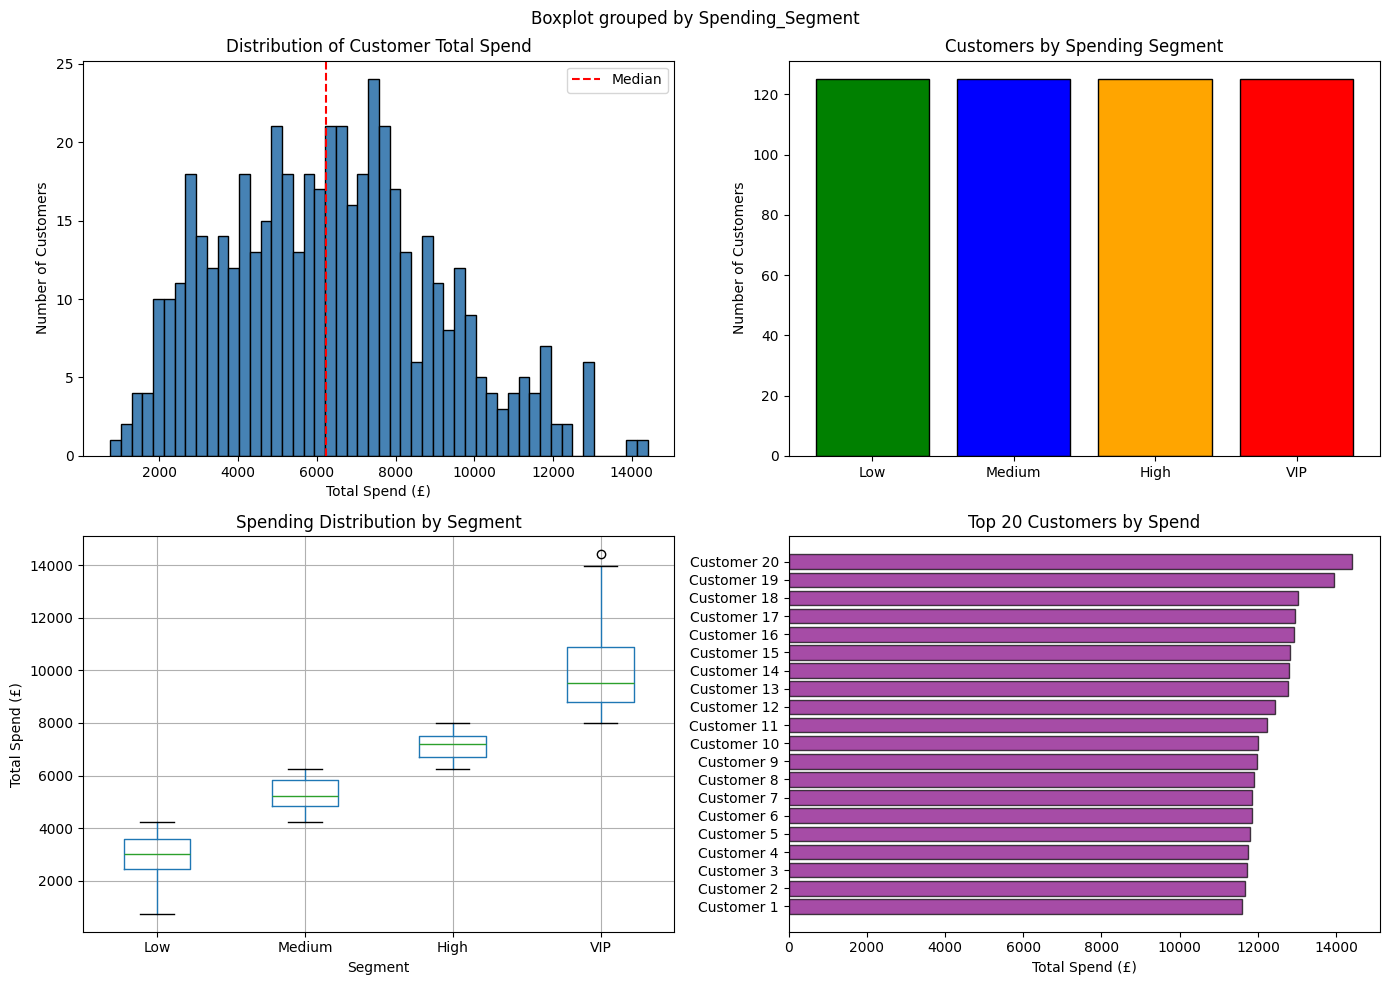


✓ Customer segmentation preview saved to reports/figures/


In [18]:
# Customer Segmentation Preview - Spending Distribution

# Calculate customer-level metrics
customer_metrics = df.groupby('CustomerID').agg({
    'Amount': ['sum', 'mean', 'count'],
    'InvoiceNo': 'nunique'
}).round(2)

customer_metrics.columns = ['Total_Spend', 'Avg_Transaction', 'Transaction_Count', 'Unique_Invoices']
customer_metrics = customer_metrics.sort_values('Total_Spend', ascending=False)

print("\n" + "=" * 60)
print("CUSTOMER SPENDING SEGMENTATION PREVIEW")
print("=" * 60)
print(f"\nTotal Customers: {len(customer_metrics)}")
print(f"\nSpending Distribution:")
print(f"  • Min spend: £{customer_metrics['Total_Spend'].min():.2f}")
print(f"  • Q1 (25%): £{customer_metrics['Total_Spend'].quantile(0.25):.2f}")
print(f"  • Median: £{customer_metrics['Total_Spend'].median():.2f}")
print(f"  • Q3 (75%): £{customer_metrics['Total_Spend'].quantile(0.75):.2f}")
print(f"  • Max spend: £{customer_metrics['Total_Spend'].max():.2f}")

# Segment customers into quartiles
customer_metrics['Spending_Segment'] = pd.qcut(customer_metrics['Total_Spend'], 
                                                q=4, 
                                                labels=['Low', 'Medium', 'High', 'VIP'])

segment_summary = customer_metrics.groupby('Spending_Segment').agg({
    'Total_Spend': ['count', 'sum', 'mean'],
    'Unique_Invoices': 'mean'
}).round(2)

print("\n\nCustomer Segments by Spending:")
print(segment_summary)

# Visualize customer spending distribution
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Customer Segmentation Preview - Spending Analysis', fontsize=14, fontweight='bold')

# 1. Distribution of Total Spend
axes[0, 0].hist(customer_metrics['Total_Spend'], bins=50, color='steelblue', edgecolor='black')
axes[0, 0].set_title('Distribution of Customer Total Spend')
axes[0, 0].set_xlabel('Total Spend (£)')
axes[0, 0].set_ylabel('Number of Customers')
axes[0, 0].axvline(customer_metrics['Total_Spend'].median(), color='red', linestyle='--', label='Median')
axes[0, 0].legend()

# 2. Spending by Segment
segment_counts = customer_metrics['Spending_Segment'].value_counts().sort_index()
axes[0, 1].bar(segment_counts.index, segment_counts.values, color=['green', 'blue', 'orange', 'red'], edgecolor='black')
axes[0, 1].set_title('Customers by Spending Segment')
axes[0, 1].set_ylabel('Number of Customers')

# 3. Box plot of spending by segment
customer_metrics.boxplot(column='Total_Spend', by='Spending_Segment', ax=axes[1, 0])
axes[1, 0].set_title('Spending Distribution by Segment')
axes[1, 0].set_xlabel('Segment')
axes[1, 0].set_ylabel('Total Spend (£)')
plt.sca(axes[1, 0])
plt.xticks(rotation=0)

# 4. Top 20 Customers
top_20 = customer_metrics.head(20)['Total_Spend'].sort_values(ascending=True)
axes[1, 1].barh(range(len(top_20)), top_20.values, color='purple', edgecolor='black', alpha=0.7)
axes[1, 1].set_yticks(range(len(top_20)))
axes[1, 1].set_yticklabels([f'Customer {i+1}' for i in range(len(top_20))])
axes[1, 1].set_title('Top 20 Customers by Spend')
axes[1, 1].set_xlabel('Total Spend (£)')

plt.tight_layout()
plt.savefig('../reports/figures/customer_segmentation_preview.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Customer segmentation preview saved to reports/figures/")

In [19]:
# Business Insights & Recommendations

print("\n" + "=" * 60)
print("BUSINESS INSIGHTS & RECOMMENDATIONS")
print("=" * 60)

# Insight 1: Customer Value Distribution
total_revenue = customer_metrics['Total_Spend'].sum()
top_20_revenue = customer_metrics.head(20)['Total_Spend'].sum()
top_20_pct = (top_20_revenue / total_revenue) * 100

print(f"\n📊 CUSTOMER VALUE CONCENTRATION:")
print(f"  • Top 20 customers generate {top_20_pct:.1f}% of revenue")
print(f"  • Top 20 revenue: £{top_20_revenue:,.2f}")
print(f"  • This suggests high concentration - focus on retention of high-value customers")

# Insight 2: Geographic Insights
usa_revenue = df[df['Country'] == 'USA']['Amount'].sum()
usa_pct = (usa_revenue / total_revenue) * 100
print(f"\n🌍 GEOGRAPHIC INSIGHTS:")
print(f"  • USA generates {usa_pct:.1f}% of revenue (top market)")
print(f"  • Opportunity: Expand in underperforming markets (e.g., smaller European countries)")

# Insight 3: Transaction Pattern Insights
avg_trans = df['Amount'].mean()
high_value_trans = len(df[df['Amount'] > avg_trans * 2]) / len(df) * 100
print(f"\n💰 TRANSACTION PATTERNS:")
print(f"  • {high_value_trans:.1f}% of transactions are double the average amount")
print(f"  • Opportunity: Create premium/bundle offerings for high-value segments")

# Insight 4: Customer Frequency
avg_freq = customer_metrics['Unique_Invoices'].mean()
high_freq_customers = len(customer_metrics[customer_metrics['Unique_Invoices'] > avg_freq * 1.5])
print(f"\n📈 REPEAT CUSTOMER INSIGHTS:")
print(f"  • {high_freq_customers} customers ({high_freq_customers/len(customer_metrics)*100:.1f}%) are frequent buyers")
print(f"  • Opportunity: Loyalty programs for repeat customers")

# Insight 5: Data Quality
data_quality = ((len(df) - len(df[df['Amount'] > outlier_threshold])) / len(df)) * 100
print(f"\n✅ DATA QUALITY ASSESSMENT:")
print(f"  • {data_quality:.1f}% of transactions are within normal range")
print(f"  • Data is clean and ready for RFM segmentation and clustering")

print("\n" + "=" * 60)
print("NEXT STEPS:")
print("=" * 60)
print("""
1. ✓ EDA Complete - Understanding of customer behavior and data quality confirmed
2. → Feature Engineering: Create RFM (Recency, Frequency, Monetary) scores
3. → Clustering: Apply K-Means to identify distinct customer segments
4. → Visualization: Create segment profiles and visualizations
5. → Business Recommendations: Develop targeted marketing strategies per segment
""")
print("=" * 60)


BUSINESS INSIGHTS & RECOMMENDATIONS

📊 CUSTOMER VALUE CONCENTRATION:
  • Top 20 customers generate 7.9% of revenue
  • Top 20 revenue: £248,391.05
  • This suggests high concentration - focus on retention of high-value customers

🌍 GEOGRAPHIC INSIGHTS:
  • USA generates 18.5% of revenue (top market)
  • Opportunity: Expand in underperforming markets (e.g., smaller European countries)

💰 TRANSACTION PATTERNS:
  • 15.4% of transactions are double the average amount
  • Opportunity: Create premium/bundle offerings for high-value segments

📈 REPEAT CUSTOMER INSIGHTS:
  • 39 customers (7.8%) are frequent buyers
  • Opportunity: Loyalty programs for repeat customers

✅ DATA QUALITY ASSESSMENT:
  • 98.9% of transactions are within normal range
  • Data is clean and ready for RFM segmentation and clustering

NEXT STEPS:

1. ✓ EDA Complete - Understanding of customer behavior and data quality confirmed
2. → Feature Engineering: Create RFM (Recency, Frequency, Monetary) scores
3. → Clustering: 